In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

# Problem : Principal Component Analysis
**Principal component analysis** (PCA) is a technique of dimensionality reduction, which linearly maps data onto a lower-dimensional space, so that the variance of the projected data in the associated dimensions would be maximized. In this problem, you will perform PCA on a dataset of face images.

In [3]:

import cv2
import numpy as np

# 1. 建立空列表，分別儲存訓練資料與測試資料
# X：影像資料（Features）
# Y：影像對應的分類標籤（Labels）
X_train, X_test = [], []
Y_train, Y_test = [], []

# 2. 讀取第 1 類到第 40 類的影像
# range(1, 41) 代表 1~40，不包含 41
for i in range(1, 41):

    # 3. 每一類讀取第 1~9 張影像作為訓練資料
    for j in range(1, 10):

        # 讀取圖片，並轉換成灰階影像
        # 例如：data/1_1.png、data/1_2.png
        img = cv2.imread('data/{}_{}.png'.format(i, j),
                         cv2.IMREAD_GRAYSCALE)

        # 將影像加入訓練資料
        X_train.append(img)

        # 將類別編號 i 加入訓練標籤
        Y_train.append(i)

    # 4. 每一類的第 10 張影像作為測試資料
    # 例如：data/1_10.png
    img = cv2.imread('data/{}_10.png'.format(i),
                     cv2.IMREAD_GRAYSCALE)

    # 將影像加入測試資料
    X_test.append(img)

    # 將對應類別編號加入測試標籤
    Y_test.append(i)

# 5. 將 Python List 轉換成 NumPy Array
# 方便後續進行機器學習模型訓練
X_train = np.array(X_train)
X_test = np.array(X_test)
Y_train = np.array(Y_train)
Y_test = np.array(Y_test)

# 6. 顯示訓練與測試資料的陣列形狀
print(X_train.shape, Y_train.shape)
print(X_test.shape, Y_test.shape)


(360, 56, 46) (360,)
(40, 56, 46) (40,)


In [4]:

# 將訓練影像資料從多維陣列轉換成二維陣列
# len(Y_train)：訓練樣本數量（360 張圖片）
# -1：讓 NumPy 自動計算每張圖片展平後的特徵數量
# reshape：將每張二維影像攤平成一維特徵向量
x = X_train.reshape(len(Y_train), -1)

# 顯示轉換後的陣列形狀
print(x.shape)


(360, 2576)


## 1. mean face & first four eigenfaces

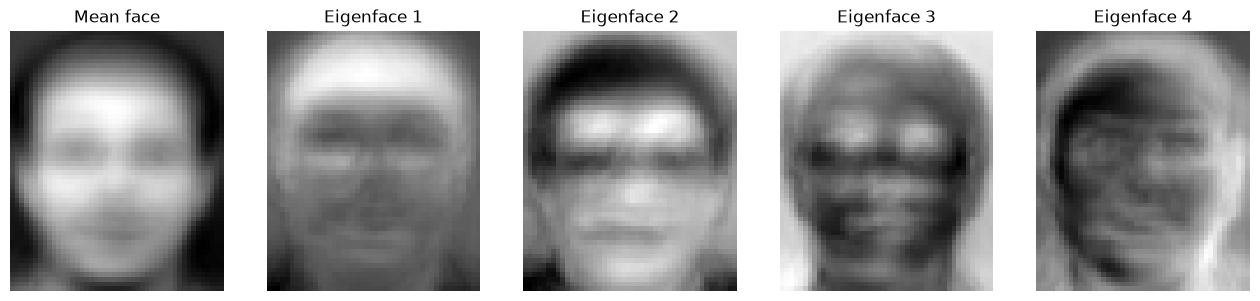

In [6]:

# 建立 PCA（主成分分析）模型
pca = PCA()

# 將訓練影像轉換成二維陣列，並使用 PCA 進行訓練
pca.fit(X_train.reshape(len(Y_train), -1))

# 設定整體圖表大小為 16 × 12
plt.figure(figsize=(16,12))

# 建立 1 列 5 欄的子圖，顯示第 1 張圖片
plt.subplot(1, 5, 1)

# 隱藏座標軸
plt.axis('off')

# 設定標題為平均人臉
plt.title("Mean face")

# 將 PCA 計算出的平均人臉還原成原始圖片形狀，並以灰階顯示
plt.imshow(pca.mean_.reshape(X_train[0].shape), cmap='gray')

# 依序顯示前 4 個主成分（Eigenfaces）
for i in range(4):

    # 設定子圖位置
    plt.subplot(1, 5, i+2)

    # 隱藏座標軸
    plt.axis('off')

    # 設定特徵臉標題，編號從 1 開始
    plt.title("Eigenface {}".format(i+1))

    # 將第 i 個 PCA 主成分還原成圖片形狀並以灰階顯示
    plt.imshow(pca.components_[i].reshape(X_train[0].shape), cmap='gray')

# 顯示圖表
plt.show()


## 2. Reconstruct person2 image1 using the first n = 3, 50, 170, 240, 345 eigenfaces
## 3. compute the mean squared error

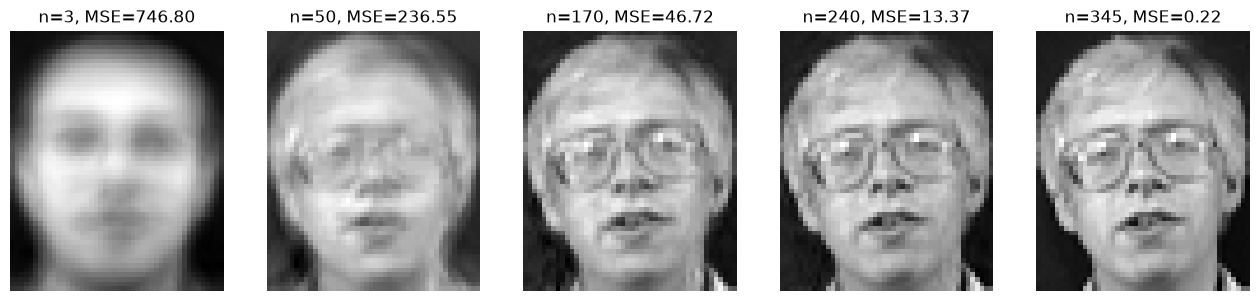

In [7]:

# 讀取指定圖片，轉換成灰階，並展平成一維特徵向量
img = cv2.imread('data/2_1.png', cv2.IMREAD_GRAYSCALE).reshape(1, -1)

# 使用已訓練的 PCA 模型，將圖片轉換成主成分係數
a = pca.transform(img)

# 建立圖表，設定圖片大小為 16 × 12
plt.figure(figsize=(16,12))

# 設定不同的 PCA 主成分數量，用於比較影像重建效果
n_components = [3, 50, 170, 240, 345]

# 依序使用不同數量的主成分重建圖片
# i：子圖索引；n：使用的主成分數量
for i, n in enumerate(n_components):

    # 建立與原始圖片相同形狀的零矩陣
    face = np.zeros(img.shape)

    # 累加前 n 個主成分，重建影像特徵
    for j in range(n):

        # 主成分係數乘上對應的主成分向量，再累加
        face = face + a[0][j]*pca.components_[j]

    # 加回 PCA 的平均人臉，完成影像重建
    face = face+pca.mean_

    # 計算重建圖片與原始圖片之間的均方誤差（MSE）
    # 差值平方後取平均，數值越小代表重建誤差越小
    MSE = np.mean((face-img)**2)

    # 將重建圖片排列成 1 列 5 欄
    plt.subplot(1, 5, i+1)

    # 隱藏座標軸
    plt.axis('off')

    # 顯示主成分數量 n 與 MSE，MSE 保留兩位小數
    plt.title("n={}, MSE={:.2f}".format(n, MSE))

    # 將重建資料還原成原始影像大小，並以灰階顯示
    plt.imshow(face.reshape(X_train[0].shape), cmap='gray')


## 4. cross-validation results

In [9]:

# ============================================================
# PCA 特徵轉換（降維）
# 目的：將原始影像轉換成 PCA 主成分特徵，供 KNN 分類使用
# ============================================================

# 將訓練影像展平成一維，再轉換為 PCA 特徵
reduced_X_train = pca.transform(X_train.reshape(len(Y_train), -1))


# ============================================================
# 設定模型測試參數
# 目的：比較不同 KNN 鄰居數量與 PCA 主成分數量的辨識效果
# ============================================================

# KNN 鄰居數量：分別測試 1、3、5
K = [1, 3, 5]

# PCA 主成分數量：分別測試 3、50、170
N = [3, 50, 170]


# ============================================================
# 隨機打亂訓練資料
# 目的：避免資料依照人物類別排列，影響交叉驗證結果
# ============================================================

# 產生隨機排列的資料索引
random = np.random.permutation(len(Y_train))

# 依照隨機索引重新排列影像特徵
reduced_X_train = reduced_X_train[random]

# 使用相同索引排列標籤，確保影像與答案一致
Y_train_random = Y_train[random]


# ============================================================
# 建立 KNN 模型，測試不同的 K 值
# 目的：找出適合的鄰居數量
# ============================================================

# 依序測試 K = 1、3、5
for k in K:

    # 顯示目前的 K 值
    print("k={}".format(k))

    # 建立 KNN 分類模型
    knn = KNeighborsClassifier(n_neighbors=k)


    # ========================================================
    # 使用不同 PCA 特徵數量進行交叉驗證
    # 目的：比較 9 種 KNN 與 PCA 組合的平均準確率
    # ========================================================

    # 依序測試 N = 3、50、170
    for n in N:

        # 顯示目前主成分數量，並保持在同一行輸出
        print('  n={}, '.format(n), end='')

        # 取前 n 個 PCA 特徵，執行 3 折交叉驗證
        score = cross_val_score(knn, reduced_X_train[:, :n], Y_train_random, cv=3)

        # 計算三次準確率的平均值，顯示至小數點後四位
        print('score={:.4f}'.format(score.mean()))



k=1
  n=3, score=0.7750
  n=50, score=0.9722
  n=170, score=0.9694
k=3
  n=3, score=0.7028
  n=50, score=0.9528
  n=170, score=0.9417
k=5
  n=3, score=0.6306
  n=50, score=0.8861
  n=170, score=0.8778


## 5. recognition rate of the testing set

In [10]:

# ============================================================
# 設定 KNN 與 PCA 的最佳參數
# 目的：使用選定的參數進行人臉辨識測試
# ============================================================

# KNN 鄰居數量設定為 1
k=1

# PCA 使用 50 個主成分特徵
n=50


# ============================================================
# 將測試影像轉換成 PCA 特徵
# 目的：讓測試資料使用與訓練資料相同的 PCA 轉換方式
# ============================================================

# 將測試圖片展平成一維，再轉換成 PCA 主成分特徵
reduced_X_test = pca.transform(X_test.reshape(len(Y_test), -1))


# ============================================================
# 建立 KNN 分類模型並進行訓練
# 目的：使用訓練資料及正確標籤，建立人臉辨識模型
# ============================================================

# 建立 KNN 模型，設定鄰居數量為 k
knn = KNeighborsClassifier(n_neighbors=k)

# 使用前 n 個 PCA 特徵與對應標籤訓練 KNN 模型
knn.fit(reduced_X_train[:, :n], Y_train_random)


# ============================================================
# 計算測試集辨識準確率（Accuracy）
# 目的：評估模型對未參與訓練的測試圖片辨識能力
# ============================================================

# 使用測試資料計算準確率，並印出結果
print('accuracy = {}'.format(knn.score(reduced_X_test[:, :n], Y_test)))


accuracy = 0.925
